# 10. Aproksymacja i transformaty dwuwymiarowe

**Arkadiusz Liber** · *Falki w praktyce. Od wzoru do kodu*

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/writingin/falki-w-praktyce-od-wzoru-do-kodu-notatniki/blob/main/rozdzial-10.ipynb)

Notatnik do książki. Zawiera wszystkie programy z tekstu rozdziału oraz ćwiczenia z rozwiązaniami.

Notatnik działa lokalnie (Jupyter) i w Google Colab. Komórki można uruchamiać po kolei poleceniem *Uruchom wszystko*.

In [1]:
# Uruchom tę komórkę jako pierwszą (lokalnie albo w Google Colab).
import sys, subprocess, importlib.util, os
if importlib.util.find_spec("pywt") is None:      # PyWavelets
    subprocess.check_call([sys.executable, "-m", "pip",
                           "install", "-q", "PyWavelets"])
import numpy as np
import matplotlib.pyplot as plt
import pywt

SZARY, NIEBIESKI, RDZAWY, ZIELONY = "#757575", "#1273E2", "#D93B0B", "#078832"
FIOLET, BURSZTYN = "#9258D5", "#B36000"
plt.rcParams.update({
    "text.color": SZARY, "axes.labelcolor": SZARY, "axes.edgecolor": SZARY,
    "xtick.color": SZARY, "ytick.color": SZARY, "axes.titlecolor": SZARY,
    "font.size": 10, "axes.titlesize": 10,
    "axes.spines.top": False, "axes.spines.right": False})

# Dane z obserwatorium SDO używane w tym rozdziale.
# Courtesy of NASA/SDO and the AIA, EVE, and HMI science teams
DANE = "dane/sdo-20240115.npz"
if not os.path.exists(DANE):                 # np. Google Colab: pobranie z repozytorium
    import urllib.request
    os.makedirs("dane", exist_ok=True)
    urllib.request.urlretrieve("https://raw.githubusercontent.com/writingin/falki-w-praktyce-od-wzoru-do-kodu-notatniki/main/dane/sdo-20240115.npz", DANE)


## Programy z tekstu rozdziału

### Kod 10.1. Rozdzielna baza Haara dla obrazów o wymiarach 4 na 4

In [2]:
import numpy as np

r = 1/np.sqrt(2)
H = np.array([[0.5, 0.5, 0.5, 0.5],          # baza Haara w R^4
              [0.5, 0.5, -0.5, -0.5],
              [r, -r, 0, 0],
              [0, 0, r, -r]])

baza = [np.outer(H[j], H[k]) for j in range(4) for k in range(4)]
G = np.array([[np.sum(a*b) for b in baza] for a in baza])
print(len(baza), np.allclose(G, np.eye(16)))    # 16 obrazów bazowych

F = np.array([[10., 10, 20, 20],
              [10, 10, 20, 20],
              [30, 30, 80, 80],
              [30, 30, 80, 40]])
C = H @ F @ H.T                                  # wzór (10.5)
print(C.round(2))
print(np.allclose(H.T @ C @ H, F),
      np.isclose(np.sum(F**2), np.sum(C**2)))

16 True
[[130.   -50.     0.    14.14]
 [-70.    30.     0.   -14.14]
 [  0.     0.     0.     0.  ]
 [ 14.14 -14.14   0.   -20.  ]]
True True


### Kod 10.2. Usuwanie nierównomiernego tła przez dopasowanie powierzchni drugiego stopnia

In [3]:
import numpy as np

n = 128
y, x = np.mgrid[0:n, 0:n]/n
rng = np.random.default_rng(1)
obiekty = np.zeros((n, n))
for _ in range(12):                       # małe jasne plamki
    cy, cx = rng.uniform(0.1, 0.9, size=2)
    obiekty += 40*np.exp(-((x - cx)**2 + (y - cy)**2)/0.0008)
tlo = 100 + 60*x - 30*y + 50*(x - 0.5)**2
obraz = obiekty + tlo + rng.normal(scale=2, size=(n, n))

X = np.stack([np.ones(n*n), x.ravel(), y.ravel(), x.ravel()**2,
              (x*y).ravel(), y.ravel()**2], axis=1)
wsp = np.linalg.lstsq(X, obraz.ravel(), rcond=None)[0]
dopasowane = (X @ wsp).reshape(n, n)
wyrownany = obraz - dopasowane

print("rozrzut tła przed:", round(float(np.ptp(tlo)), 1))
print("błąd dopasowania tła (odch. std.):",
      round(float(np.std(dopasowane - tlo)), 2))
prog = 15
print("punktów powyżej progu po wyrównaniu:",
      int(np.sum(wyrownany > prog)), " prawdziwych:",
      int(np.sum(obiekty > prog)))

rozrzut tła przed: 88.9
błąd dopasowania tła (odch. std.): 0.9
punktów powyżej progu po wyrównaniu: 424  prawdziwych: 473


### Kod 10.3. Pociemnienie brzegowe: dopasowanie modelu i wyszukanie plam

In [4]:
import numpy as np
from scipy import ndimage

T = np.nan_to_num(np.load("dane/sdo-20240115.npz")["hmi_ic_tarcza"])
srodek = np.median(T[240:272, 240:272])
tarcza = T > 0.3*srodek                        # punkty tarczy
wy, wx = np.nonzero(tarcza)
cy, cx, R = wy.mean(), wx.mean(), np.sqrt(tarcza.sum()/np.pi)
print(f"środek ({cx:.1f}, {cy:.1f}), promień {R:.1f} punktu")

y, x = np.mgrid[0:512, 0:512]
r2 = ((x - cx)**2 + (y - cy)**2)/R**2
mu = np.sqrt(np.clip(1 - r2, 0, None))
maska = r2 < 0.97**2                           # bez samego brzegu

def dopasuj(m):
    X = np.stack([np.ones(m.sum()), mu[m], mu[m]**2], axis=1)
    a = np.linalg.lstsq(X, T[m], rcond=None)[0]
    return a, a[0] + a[1]*mu + a[2]*mu**2

a, model = dopasuj(maska)
wzgl = np.where(maska, T/model - 1, 0)         # odchyłka względna
a, model = dopasuj(maska & (np.abs(wzgl) < 0.05))    # bez plam
wzgl = np.where(maska, T/model - 1, 0)

print("współczynniki:", np.round(a/a.sum(), 3))
print(f"rozrzut jasności tarczy: {100*np.std(T[maska]/T[maska].mean()):.1f}%"
      f", po podzieleniu przez model: {100*np.std(wzgl[maska]):.1f}%")
ciemne = wzgl < -0.1
grupy, ile = ndimage.label(ciemne)
pola = ndimage.sum(ciemne, grupy, range(1, ile + 1))
print("punktów ciemniejszych o 10% od modelu:", int(ciemne.sum()),
      " grup co najmniej 5 punktów:", int(np.sum(pola >= 5)))
print("punktów poniżej stałego progu 0,9 jasności środka:",
      int(np.sum(T[maska] < 0.9*srodek)), "z", int(maska.sum()))

środek (256.4, 255.3), promień 241.8 punktu
współczynniki: [ 0.393  0.814 -0.207]
rozrzut jasności tarczy: 13.2%, po podzieleniu przez model: 2.0%
punktów ciemniejszych o 10% od modelu: 347  grup co najmniej 5 punktów: 10
punktów poniżej stałego progu 0,9 jasności środka: 102154 z 172768


### Kod 10.4. Powiększanie obrazu trzema metodami interpolacji

In [5]:
import numpy as np
from scipy import ndimage

def funkcja(n):
    y, x = (np.mgrid[0:n, 0:n] + 0.5)/n       # środki punktów
    return np.sin(6*x + 2*np.sin(5*y)) + 0.5*np.cos(9*y*x)

maly, wzorzec = funkcja(32), funkcja(256)
for rzad, nazwa in ((0, "najbliższy sąsiad"), (1, "dwuliniowa"),
                    (3, "dwusześcienna")):
    duzy = ndimage.zoom(maly, 8, order=rzad, mode="nearest",
                        grid_mode=True)
    blad = np.sqrt(np.mean((duzy - wzorzec)[16:-16, 16:-16]**2))
    print(f"{nazwa:18s} błąd średniokwadratowy {blad:.4f}")

najbliższy sąsiad  błąd średniokwadratowy 0.0603
dwuliniowa         błąd średniokwadratowy 0.0060
dwusześcienna      błąd średniokwadratowy 0.0006


### Kod 10.5. Przybliżenie obrazu macierzą niskiego rzędu

In [6]:
import numpy as np

dane = np.load("dane/sdo-20240115.npz")["aia171"]
F = 255*np.sqrt(dane/dane.max())             # skala pierwiastkowa
U, s, Vt = np.linalg.svd(F, full_matrices=False)

for k in (5, 20, 50, 100):
    Fk = (U[:, :k]*s[:k]) @ Vt[:k]
    blad = np.linalg.norm(F - Fk)/np.linalg.norm(F)
    ze_wzoru = np.sqrt(np.sum(s[k:]**2))/np.linalg.norm(F)
    liczby = k*(F.shape[0] + F.shape[1] + 1)
    print(f"rząd {k:3d}: błąd {100*blad:5.2f}% (wzór: "
          f"{100*ze_wzoru:5.2f}%), pamięć {100*liczby/F.size:4.1f}%")

rząd   5: błąd 11.05% (wzór: 11.05%), pamięć  2.0%
rząd  20: błąd  5.36% (wzór:  5.36%), pamięć  7.8%
rząd  50: błąd  3.01% (wzór:  3.01%), pamięć 19.6%
rząd 100: błąd  1.82% (wzór:  1.82%), pamięć 39.1%


### Kod 10.6. Widmo obrazu i filtr dolnoprzepustowy w dziedzinie częstotliwości

In [7]:
import numpy as np

dane = np.load("dane/sdo-20240115.npz")["aia171"]
F = 255*np.sqrt(dane/dane.max())             # skala pierwiastkowa
widmo = np.fft.fftshift(np.fft.fft2(F))        # zero częstotliwości w środku
print(np.isclose(np.sum(F**2), np.sum(np.abs(widmo)**2)/F.size))

M, N = F.shape
k, l = np.mgrid[-M//2:M//2, -N//2:N//2]
promien = np.hypot(k, l)
moc = np.abs(widmo)**2
for R in (8, 32, 128):
    udzial = moc[promien <= R].sum()/moc.sum()
    print(f"promień {R:3d}: {100*np.mean(promien <= R):5.2f}% "
          f"współczynników, {100*udzial:6.3f}% energii")

dolne = np.fft.ifft2(np.fft.ifftshift(widmo*(promien <= 32))).real
print("błąd po filtracji:",
      round(float(np.linalg.norm(F - dolne)/np.linalg.norm(F)), 4))

True
promień   8:  0.08% współczynników, 98.465% energii
promień  32:  1.22% współczynników, 99.643% energii
promień 128: 19.62% współczynników, 99.953% energii
błąd po filtracji: 0.0598


### Kod 10.7. Jeden stopień dwuwymiarowej transformaty Haara: z definicji i z biblioteki

In [8]:
import numpy as np
import pywt

def haar2(F):
    a, b = F[0::2, 0::2], F[0::2, 1::2]       # lewy górny, prawy górny
    c, d = F[1::2, 0::2], F[1::2, 1::2]       # lewy dolny, prawy dolny
    return ((a + b + c + d)/2, (a + b - c - d)/2,
            (a - b + c - d)/2, (a - b - c + d)/2)

F = np.array([[10., 10, 20, 20],
              [10, 10, 20, 20],
              [30, 30, 80, 80],
              [30, 30, 80, 40]])
cA, cH, cV, cD = haar2(F)
print(cA, cH, cV, cD, sep="\n")

A, (H, V, D) = pywt.dwt2(F, "haar")
print(np.allclose(cA, A), np.allclose(cH, H),
      np.allclose(cV, V), np.allclose(cD, D))
print(np.allclose(pywt.idwt2((A, (H, V, D)), "haar"), F))

# to samo jako dwie serie transformat jednowymiarowych
dol, gora = pywt.dwt(F, "haar", axis=1)        # wzdłuż wierszy
print(np.allclose(pywt.dwt(dol, "haar", axis=0)[1], H))

[[ 20.  40.]
 [ 60. 140.]]
[[ 0.  0.]
 [ 0. 20.]]
[[ 0.  0.]
 [ 0. 20.]]
[[  0.   0.]
 [  0. -20.]]
True True True True
True
True


### Kod 10.8. Wielopoziomowa dwuwymiarowa transformata falkowa

In [9]:
import numpy as np
import pywt

dane = np.load("dane/sdo-20240115.npz")["aia171"]
F = 255*np.sqrt(dane/dane.max())             # skala pierwiastkowa
wsp = pywt.wavedec2(F, "sym4", level=3, mode="periodization")

print("cA3:", wsp[0].shape)
energia = np.sum(F**2)
print(f"energia cA3: {100*np.sum(wsp[0]**2)/energia:.2f}%")
for poziom, (cH, cV, cD) in zip((3, 2, 1), wsp[1:]):
    e = [100*np.sum(c**2)/energia for c in (cH, cV, cD)]
    print(f"poziom {poziom}: {cH.shape}, energia cH {e[0]:.3f}%, "
          f"cV {e[1]:.3f}%, cD {e[2]:.3f}%")

tablica, uklad = pywt.coeffs_to_array(wsp)       # jedna tablica
print(tablica.shape, np.isclose(np.sum(tablica**2), energia))
odtworzony = pywt.waverec2(wsp, "sym4", mode="periodization")
print(np.allclose(odtworzony, F))
male = np.mean(np.abs(tablica) < 0.01*np.abs(tablica).max())
print(f"współczynników mniejszych niż 1% największego: {100*male:.1f}%")

cA3: (64, 64)
energia cA3: 99.64%
poziom 3: (64, 64), energia cH 0.076%, cV 0.115%, cD 0.020%
poziom 2: (128, 128), energia cH 0.038%, cV 0.047%, cD 0.010%
poziom 1: (256, 256), energia cH 0.018%, cV 0.024%, cD 0.007%
(512, 512) True
True
współczynników mniejszych niż 1% największego: 97.4%


### Kod 10.9. Kompresja obrazu przez zachowanie 5% liczb: falki, transformata kosinusowa i macierz niskiego rzędu

In [10]:
import numpy as np
import pywt
from scipy.fft import dctn, idctn

dane = np.load("dane/sdo-20240115.npz")["aia171"]
F = 255*np.sqrt(dane/dane.max())             # skala pierwiastkowa
psnr = lambda G: 10*np.log10(255**2/np.mean((F - G)**2))
K = F.size//20                                   # 5% liczb

def najwieksze(c, K):
    prog = np.sort(np.abs(c).ravel())[-K]
    return np.where(np.abs(c) >= prog, c, 0)

wsp = pywt.wavedec2(F, "bior4.4", level=5, mode="periodization")
tab, uklad = pywt.coeffs_to_array(wsp)
falki = pywt.waverec2(pywt.array_to_coeffs(
    najwieksze(tab, K), uklad, output_format="wavedec2"),
    "bior4.4", mode="periodization")

kosinusy = idctn(najwieksze(dctn(F, norm="ortho"), K), norm="ortho")

U, s, Vt = np.linalg.svd(F, full_matrices=False)
k = K//(sum(F.shape) + 1)                        # rząd o tej samej pamięci
niski_rzad = (U[:, :k]*s[:k]) @ Vt[:k]

for nazwa, G in (("falki bior4.4", falki),
                 ("transformata kosinusowa", kosinusy),
                 (f"macierz rzędu {k}", niski_rzad)):
    print(f"{nazwa:24s} PSNR {psnr(G):5.2f} dB, największy błąd "
          f"{np.abs(F - G).max():5.1f}")

falki bior4.4            PSNR 41.97 dB, największy błąd  13.4
transformata kosinusowa  PSNR 40.82 dB, największy błąd  48.3
macierz rzędu 12         PSNR 32.52 dB, największy błąd  75.3


### Kod 10.10. Odszumianie obrazu: filtr Gaussa, progowanie w transformacie zwykłej i stacjonarnej

In [11]:
import numpy as np
import pywt
from scipy import ndimage

def scena(n=256):
    y, x = np.mgrid[0:n, 0:n]/n
    F = 60 + 80*x + 40*np.sin(2*np.pi*y)*x                   # tło
    F += 90*((x - 0.3)**2 + (y - 0.35)**2 < 0.15**2)         # koło
    F -= 50*((np.abs(x - 0.7) < 0.15) & (np.abs(y - 0.65) < 0.2))
    pas = y - 0.15*(x - 0.5)
    F += 70*((pas > 0.75) & (pas < 0.8))                     # ukośny pas
    return np.clip(F, 0, 255)

def prog_dwt(Z, falka, poziomy=4, k=3.0):
    wsp = pywt.wavedec2(Z, falka, level=poziomy, mode="periodization")
    sigma = np.median(np.abs(wsp[-1][2]))/0.6745             # wzór (7.7)
    wsp = [wsp[0]] + [tuple(pywt.threshold(c, k*sigma, "hard")
                            for c in detale) for detale in wsp[1:]]
    return pywt.waverec2(wsp, falka, mode="periodization")

def prog_swt(Z, falka, poziomy=3, k=3.0, sigma=None):
    wsp = pywt.swt2(Z, falka, level=poziomy, norm=True)
    if sigma is None:                    # detale poziomu 1: szum sigma/2
        sigma = 2*np.median(np.abs(wsp[-1][1][2]))/0.6745
    wynik = []
    for nr, (cA, detale) in enumerate(wsp):
        prog = k*sigma/2**(poziomy - nr)                     # poziom j
        wynik.append((cA, tuple(pywt.threshold(c, prog, "hard")
                                for c in detale)))
    return pywt.iswt2(wynik, falka, norm=True)

F = scena()
rng = np.random.default_rng(0)
Z = F + 15*rng.normal(size=F.shape)
psnr = lambda G: 10*np.log10(255**2/np.mean((F - G)**2))

print(f"obraz zaszumiony      {psnr(Z):5.2f} dB")
for s in (1.0, 1.5):
    G = ndimage.gaussian_filter(Z, s)
    print(f"filtr Gaussa, s = {s}   {psnr(G):5.2f} dB")
for falka in ("haar", "sym4"):
    print(f"DWT, {falka:5s}           {psnr(prog_dwt(Z, falka)):5.2f} dB")
for falka in ("haar", "sym4"):
    print(f"SWT, {falka:5s}           {psnr(prog_swt(Z, falka)):5.2f} dB")

obraz zaszumiony      24.61 dB
filtr Gaussa, s = 1.0   32.68 dB
filtr Gaussa, s = 1.5   32.62 dB
DWT, haar            34.14 dB
DWT, sym4            32.91 dB
SWT, haar            38.81 dB
SWT, sym4            35.90 dB


### Kod 10.11. Szum fotonowy: stabilizacja wariancji i odszumianie

In [12]:
import numpy as np
import pywt
from scipy import ndimage

anscombe = lambda x: 2*np.sqrt(x + 3/8)
odwrotna = lambda y: (y/2)**2 - 1/8

rng = np.random.default_rng(0)
for srednia in (1, 2, 5, 20, 100):
    n = rng.poisson(srednia, 200000)
    print(f"średnia {srednia:3d}: odchylenie {n.std():5.2f}, "
          f"po przekształceniu {anscombe(n).std():.3f}")

def prog_swt(Z, falka, poziomy=3, k=3.0, sigma=None):       # z kodu 10.10
    wsp = pywt.swt2(Z, falka, level=poziomy, norm=True)
    if sigma is None:
        sigma = 2*np.median(np.abs(wsp[-1][1][2]))/0.6745
    wynik = []
    for nr, (cA, detale) in enumerate(wsp):
        prog = k*sigma/2**(poziomy - nr)
        wynik.append((cA, tuple(pywt.threshold(c, prog, "hard")
                                for c in detale)))
    return pywt.iswt2(wynik, falka, norm=True)

I = np.load("dane/sdo-20240115.npz")["aia171"]
wzorzec = 5*I/np.median(I)               # średnia liczba zliczeń
Z = rng.poisson(wzorzec).astype(float)

ciemne = wzorzec < np.median(wzorzec)
jasne = wzorzec > np.quantile(wzorzec, 0.9)
def raport(nazwa, G):
    blad = lambda m: np.sqrt(np.mean((G - wzorzec)[m]**2))
    print(f"{nazwa:24s} całość {blad(wzorzec > 0):.2f}, ciemne "
          f"{blad(ciemne):.2f}, jasne {blad(jasne):.2f}")

raport("obraz zaszumiony", Z)
raport("filtr Gaussa, s = 1,5", ndimage.gaussian_filter(Z, 1.5))
raport("SWT bez stabilizacji", prog_swt(Z, "sym4"))
raport("Anscombe i SWT",
       odwrotna(prog_swt(anscombe(Z), "sym4", sigma=1.0)))

średnia   1: odchylenie  1.00, po przekształceniu 0.846
średnia   2: odchylenie  1.42, po przekształceniu 0.963
średnia   5: odchylenie  2.24, po przekształceniu 1.002
średnia  20: odchylenie  4.47, po przekształceniu 1.000
średnia 100: odchylenie  9.99, po przekształceniu 0.999
obraz zaszumiony         całość 2.71, ciemne 1.84, jasne 4.91
filtr Gaussa, s = 1,5    całość 0.77, ciemne 0.42, jasne 1.63
SWT bez stabilizacji     całość 1.31, ciemne 0.39, jasne 3.46
Anscombe i SWT           całość 0.78, ciemne 0.41, jasne 1.65


### Kod 10.12. Poziom szumu w rzeczywistych obrazach po transformacie Anscombe'a

In [13]:
import numpy as np
import pywt

anscombe = lambda x: 2*np.sqrt(x + 3/8)
dane = np.load("dane/sdo-20240115.npz")
for nazwa in ("aia171", "aia94"):
    I = np.clip(dane[nazwa], 0, None)
    cD = pywt.dwt2(anscombe(I), "sym4", mode="periodization")[1][2]
    sigma = np.median(np.abs(cD))/0.6745
    print(f"{nazwa}: mediana {np.median(I):6.1f}, największa wartość "
          f"{I.max():6.0f}, sigma po przekształceniu {sigma:.2f}")

aia171: mediana  312.0, największa wartość   4142, sigma po przekształceniu 0.70
aia94: mediana    5.0, największa wartość     52, sigma po przekształceniu 0.73


### Kod 10.13. Magnetogram: rzadkość, poziom szumu i zachowanie strumienia przy progowaniu

In [14]:
import numpy as np
import pywt

B = np.load("dane/sdo-20240115.npz")["hmi_m"].astype(float)
print(f"zakres od {B.min():.0f} do {B.max():.0f} G, "
      f"punktów o |B| < 50 G: {100*np.mean(np.abs(B) < 50):.1f}%")

wsp = pywt.wavedec2(B, "sym4", level=4, mode="periodization")
sigma = np.median(np.abs(wsp[-1][2]))/0.6745
print(f"oszacowany poziom szumu: {sigma:.1f} G")

tab, uklad = pywt.coeffs_to_array(wsp)
prog = np.sort(np.abs(tab).ravel())[-tab.size//20]
G = pywt.waverec2(pywt.array_to_coeffs(
    np.where(np.abs(tab) >= prog, tab, 0), uklad,
    output_format="wavedec2"), "sym4", mode="periodization")
print(f"5% współczynników: błąd względny "
      f"{100*np.linalg.norm(B - G)/np.linalg.norm(B):.1f}%, "
      f"największy {np.abs(B - G).max():.0f} G")

odsz = [wsp[0]] + [tuple(pywt.threshold(c, 3*sigma, "hard")
                         for c in detale) for detale in wsp[1:]]
niezerowe = wsp[0].size + sum(np.count_nonzero(c)
                              for detale in odsz[1:] for c in detale)
G = pywt.waverec2(odsz, "sym4", mode="periodization")
print(f"po progowaniu zostaje {100*niezerowe/B.size:.1f}% współczynników")
print(f"strumień wypadkowy: {B.sum():.0f} i {G.sum():.0f}")
silne = np.abs(B) > 200
for nazwa, m in (("pola silne", silne), ("pola słabe", ~silne)):
    przed, po = np.abs(B[m]).sum(), np.abs(G[m]).sum()
    print(f"{nazwa} ({100*m.mean():4.1f}% punktów): strumień "
          f"bezwzględny zmienia się o {100*(po/przed - 1):+.1f}%")

zakres od -2140 do 1156 G, punktów o |B| < 50 G: 85.7%
oszacowany poziom szumu: 8.8 G
5% współczynników: błąd względny 8.8%, największy 103 G
po progowaniu zostaje 11.8% współczynników
strumień wypadkowy: -1803393 i -1803393
pola silne ( 5.8% punktów): strumień bezwzględny zmienia się o -0.1%
pola słabe (94.2% punktów): strumień bezwzględny zmienia się o -15.9%


## Ćwiczenia i rozwiązania

### Ćwiczenie 10.1
Zbuduj rozdzielną bazę kosinusową dla obrazów 8 na 8 i narysuj jej 64 obrazy bazowe.

### Rozwiązanie 10.1

True


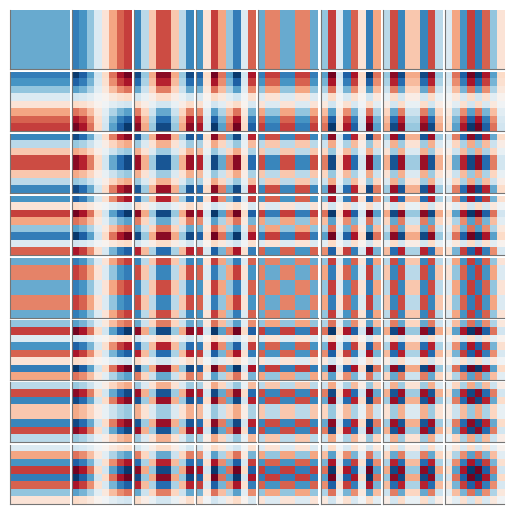

In [15]:
from scipy.fft import idct
Cm = idct(np.eye(8), norm="ortho", axis=0).T       # wiersze: wektory bazy
print(np.allclose(Cm @ Cm.T, np.eye(8)))
fig, axs = plt.subplots(8, 8, figsize=(5, 5))
for j in range(8):
    for k in range(8):
        axs[j, k].imshow(np.outer(Cm[j], Cm[k]), cmap="RdBu", vmin=-0.25, vmax=0.25)
        axs[j, k].set_xticks([]); axs[j, k].set_yticks([])
plt.tight_layout(pad=0.2); plt.show()

### Ćwiczenie 10.2
Dopasuj do danych z kodu 10.2 płaszczyznę zamiast powierzchni drugiego stopnia. Jak zmienia się błąd odtworzenia tła?

### Rozwiązanie 10.2

In [16]:
n = 128
y, x = np.mgrid[0:n, 0:n]/n
rng = np.random.default_rng(1)
obiekty = np.zeros((n, n))
for _ in range(12):
    cy, cx = rng.uniform(0.1, 0.9, size=2)
    obiekty += 40*np.exp(-((x - cx)**2 + (y - cy)**2)/0.0008)
tlo = 100 + 60*x - 30*y + 50*(x - 0.5)**2
obraz = obiekty + tlo + rng.normal(scale=2, size=(n, n))
kolumny = [np.ones(n*n), x.ravel(), y.ravel(), x.ravel()**2, (x*y).ravel(), y.ravel()**2]
for nazwa, ile in (("płaszczyzna", 3), ("drugi stopień", 6)):
    X = np.stack(kolumny[:ile], axis=1)
    d = (X @ np.linalg.lstsq(X, obraz.ravel(), rcond=None)[0]).reshape(n, n)
    print(f"{nazwa:14s} błąd tła: {np.std(d - tlo):.2f}")

płaszczyzna    błąd tła: 3.73
drugi stopień  błąd tła: 0.90


### Ćwiczenie 10.3
Sprawdź twierdzenie Eckarta–Younga dla losowej macierzy 20 na 30: porównaj błąd przybliżenia rzędu 5 otrzymanego z SVD z błędem przybliżeń rzędu 5 w tysiącu losowo wybranych podprzestrzeni.

### Rozwiązanie 10.3

In [17]:
rng = np.random.default_rng(0)
A = rng.normal(size=(20, 30))
U, s, Vt = np.linalg.svd(A, full_matrices=False)
blad_svd = np.sqrt(np.sum(s[5:]**2))
najlepszy_losowy = np.inf
for _ in range(1000):
    Q = np.linalg.qr(rng.normal(size=(20, 5)))[0]    # losowa podprzestrzeń kolumn
    najlepszy_losowy = min(najlepszy_losowy, np.linalg.norm(A - Q @ (Q.T @ A)))
print("SVD:", round(blad_svd, 3), " najlepsza z 1000 losowych:", round(najlepszy_losowy, 3))

SVD: 15.888  najlepsza z 1000 losowych: 19.795


### Ćwiczenie 10.4
Oblicz ręcznie jeden stopień dwuwymiarowej transformaty Haara obrazu o wierszach (1, 3, 5, 7), (1, 3, 5, 7), (2, 2, 6, 6), (0, 4, 8, 4). Wynik sprawdź funkcją `pywt.dwt2`.

### Rozwiązanie 10.4

In [18]:
F4 = np.array([[1., 3, 5, 7], [1, 3, 5, 7], [2, 2, 6, 6], [0, 4, 8, 4]])
cA, (cH, cV, cD) = pywt.dwt2(F4, "haar")
for nazwa, c in (("cA", cA), ("cH", cH), ("cV", cV), ("cD", cD)):
    print(nazwa, np.round(c, 6).tolist())

cA [[4.0, 12.0], [4.0, 12.0]]
cH [[0.0, 0.0], [0.0, 0.0]]
cV [[-2.0, -2.0], [-2.0, 2.0]]
cD [[0.0, 0.0], [2.0, -2.0]]


### Ćwiczenie 10.5
Wyznacz trzypoziomową transformatę obrazu pętli koronalnych z kodu 10.8, wyzeruj kolejno wszystkie detale poziome, wszystkie pionowe i wszystkie ukośne i odtwórz obraz. Które struktury znikają?

### Rozwiązanie 10.5

bez cH PSNR: 38.36 dB
bez cV PSNR: 36.86 dB
bez cD PSNR: 43.87 dB


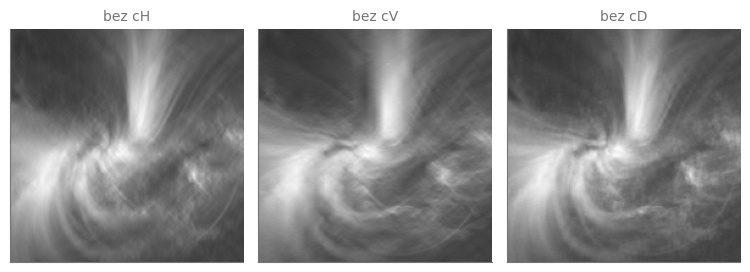

In [19]:
SDO = np.load("dane/sdo-20240115.npz")   # Courtesy of NASA/SDO and the AIA, EVE, and HMI science teams
F = 255*np.sqrt(SDO["aia171"]/SDO["aia171"].max())
wsp = pywt.wavedec2(F, "sym4", level=3, mode="periodization")
fig, axs = plt.subplots(1, 3, figsize=(7.6, 2.7))
for ax, ktory, nazwa in zip(axs, range(3), ("bez cH", "bez cV", "bez cD")):
    w = [wsp[0]] + [tuple(np.zeros_like(c) if i == ktory else c
                          for i, c in enumerate(det)) for det in wsp[1:]]
    G = pywt.waverec2(w, "sym4", mode="periodization")
    ax.imshow(G[160:352, 200:392], cmap="gray", vmin=0, vmax=255)
    ax.set_title(nazwa); ax.set_xticks([]); ax.set_yticks([])
    print(nazwa, "PSNR:", round(10*np.log10(255**2/np.mean((F - G)**2)), 2), "dB")
plt.tight_layout(); plt.show()
# Bez cH rozmywają się pętle biegnące poziomo, bez cV pętle biegnące pionowo,
# bez cD odcinki ukośne; strata jest wtedy najmniejsza.

### Ćwiczenie 10.6
Powtórz doświadczenie z kodu 10.10 dla obrazu pętli koronalnych i szumu o odchyleniu standardowym 15 i 25. Która metoda jest najlepsza i dlaczego wynik różni się od otrzymanego dla sceny syntetycznej?

### Rozwiązanie 10.6

In [20]:
from scipy import ndimage
def prog_dwt(Z, falka, poziomy=4, k=3.0):
    wsp = pywt.wavedec2(Z, falka, level=poziomy, mode="periodization")
    sigma = np.median(np.abs(wsp[-1][2]))/0.6745
    wsp = [wsp[0]] + [tuple(pywt.threshold(c, k*sigma, "hard") for c in d)
                      for d in wsp[1:]]
    return pywt.waverec2(wsp, falka, mode="periodization")
def prog_swt(Z, falka, poziomy=3, k=3.0, sigma=None):
    wsp = pywt.swt2(Z, falka, level=poziomy, norm=True)
    if sigma is None:
        sigma = 2*np.median(np.abs(wsp[-1][1][2]))/0.6745
    wynik = []
    for nr, (cA, detale) in enumerate(wsp):
        prog = k*sigma/2**(poziomy - nr)
        wynik.append((cA, tuple(pywt.threshold(c, prog, "hard") for c in detale)))
    return pywt.iswt2(wynik, falka, norm=True)
psnr = lambda G: 10*np.log10(255**2/np.mean((F - G)**2))
rng = np.random.default_rng(0)
for sigma in (15, 25):
    Z = F + sigma*rng.normal(size=F.shape)
    print(f"sigma = {sigma}: zaszumiony {psnr(Z):.2f}",
          " | Gauss 1,5:", round(psnr(ndimage.gaussian_filter(Z, 1.5)), 2),
          " | Gauss 2,0:", round(psnr(ndimage.gaussian_filter(Z, 2.0)), 2),
          " | DWT haar:", round(psnr(prog_dwt(Z, "haar")), 2),
          " | DWT sym4:", round(psnr(prog_dwt(Z, "sym4")), 2),
          " | SWT haar:", round(psnr(prog_swt(Z, "haar")), 2),
          " | SWT sym4:", round(psnr(prog_swt(Z, "sym4")), 2))
# Pętle korony są gładkie i nie mają ostrych krawędzi, więc filtr Gaussa
# o dobrze dobranej szerokości dorównuje progowaniu w transformacie stacjonarnej.

sigma = 15: zaszumiony 24.60  | Gauss 1,5: 36.48  | Gauss 2,0: 36.48  | DWT haar: 32.62  | DWT sym4: 33.71  | SWT haar: 36.33  | SWT sym4: 36.36
sigma = 25: zaszumiony 20.16  | Gauss 1,5: 33.42  | Gauss 2,0: 34.47  | DWT haar: 30.22  | DWT sym4: 31.08  | SWT haar: 34.04  | SWT sym4: 33.85


### Ćwiczenie 10.7
Narysuj wykres PSNR w funkcji odsetka zachowanych współczynników (od 1% do 20%) dla falek haar, db2, sym4 i bior4.4.

### Rozwiązanie 10.7

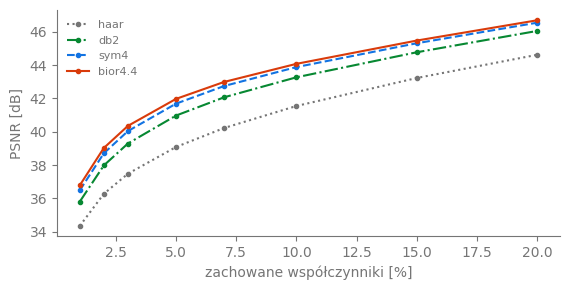

In [21]:
odsetki = np.array([1, 2, 3, 5, 7, 10, 15, 20])
fig, ax = plt.subplots(figsize=(5.8, 3.0))
for falka, kol, ls in (("haar", SZARY, ":"), ("db2", ZIELONY, "-."),
                       ("sym4", NIEBIESKI, "--"), ("bior4.4", RDZAWY, "-")):
    wsp = pywt.wavedec2(F, falka, level=5, mode="periodization")
    tab, uklad = pywt.coeffs_to_array(wsp)
    posortowane = np.sort(np.abs(tab).ravel())[::-1]
    wyniki = []
    for o in odsetki:
        prog = posortowane[F.size*o//100]
        G = pywt.waverec2(pywt.array_to_coeffs(np.where(np.abs(tab) > prog, tab, 0),
                          uklad, output_format="wavedec2"), falka, mode="periodization")
        wyniki.append(psnr(G))
    ax.plot(odsetki, wyniki, color=kol, ls=ls, marker="o", ms=3, label=falka)
ax.set_xlabel("zachowane współczynniki [%]"); ax.set_ylabel("PSNR [dB]")
ax.legend(frameon=False, fontsize=8); plt.tight_layout(); plt.show()

### Ćwiczenie 10.8
Zaimplementuj całkowitoliczbową dwuwymiarową transformatę 5/3, stosując krok liftingu do wierszy i kolumn. Sprawdź dokładną odwracalność na wycinku z plamą słoneczną (tablica `hmi_ic_plama`) zaokrąglonym do liczb całkowitych.

### Rozwiązanie 10.8

In [22]:
def krok(x):                                   # wzdłuż ostatniej osi
    e, o = x[..., 0::2], x[..., 1::2]
    d = o - (e + np.roll(e, -1, axis=-1))//2
    return e + (np.roll(d, 1, axis=-1) + d + 2)//4, d

def krok_odwrotny(s, d):
    e = s - (np.roll(d, 1, axis=-1) + d + 2)//4
    x = np.empty(s.shape[:-1] + (2*s.shape[-1],), dtype=s.dtype)
    x[..., 0::2], x[..., 1::2] = e, d + (e + np.roll(e, -1, axis=-1))//2
    return x

obraz = np.round(SDO["hmi_ic_plama"]).astype(np.int64)
dol, gora = krok(obraz)                        # wiersze
cA, cH = (c.T for c in krok(dol.T))            # kolumny części dolnej
cV, cD = (c.T for c in krok(gora.T))           # kolumny części górnej
print(cA.dtype, cA.shape, "zakres obrazu:", int(obraz.min()), int(obraz.max()),
      " największy |detal|:", int(max(np.abs(c).max() for c in (cH, cV, cD))))
dol2 = krok_odwrotny(cA.T, cH.T).T
gora2 = krok_odwrotny(cV.T, cD.T).T
print("dokładna odwracalność:", np.array_equal(krok_odwrotny(dol2, gora2), obraz))

int64 (256, 256) zakres obrazu: 6698 55970  największy |detal|: 5020
dokładna odwracalność: True


### Ćwiczenie 10.9
Powtórz doświadczenie z kodu 10.11 dla obrazów wzorcowych o medianie 1, 5, 20 i 100 zliczeń. Jak zysk ze stabilizacji wariancji zależy od liczby zliczeń?

### Rozwiązanie 10.9

In [23]:
anscombe = lambda x: 2*np.sqrt(x + 3/8)
odwrotna = lambda y: (y/2)**2 - 1/8
I = SDO["aia171"]
for mediana in (1, 5, 20, 100):
    wzorzec = mediana*I/np.median(I)
    Z = np.random.default_rng(0).poisson(wzorzec).astype(float)
    blad = lambda G: np.sqrt(np.mean((G - wzorzec)**2))/mediana
    print(f"mediana {mediana:3d}: błąd względem mediany: dane {blad(Z):.3f}, "
          f"bez stabilizacji {blad(prog_swt(Z, 'sym4')):.3f}, "
          f"ze stabilizacją {blad(odwrotna(prog_swt(anscombe(Z), 'sym4', sigma=1.0))):.3f}")
# Zysk maleje ze wzrostem liczby zliczeń: przy medianie 1 stabilizacja zmniejsza
# błąd ponad dwukrotnie, przy medianie 100 już tylko o jedną dziesiątą. Im więcej
# zliczeń, tym mniejszy jest szum w porównaniu ze strukturami obrazu.

mediana   1: błąd względem mediany: dane 1.214, bez stabilizacji 0.554, ze stabilizacją 0.245
mediana   5: błąd względem mediany: dane 0.543, bez stabilizacji 0.260, ze stabilizacją 0.158
mediana  20: błąd względem mediany: dane 0.271, bez stabilizacji 0.146, ze stabilizacją 0.110
mediana 100: błąd względem mediany: dane 0.121, bez stabilizacji 0.082, ze stabilizacją 0.074


### Ćwiczenie 10.10
Dopasuj do tarczy Słońca model liniowy $I = a_0 + a_1 \mu$ i porównaj rozrzut odchyłek z otrzymanym dla modelu (10.8).

### Rozwiązanie 10.10

In [24]:
T = np.nan_to_num(SDO["hmi_ic_tarcza"])
srodek = np.median(T[240:272, 240:272])
tarcza = T > 0.3*srodek
wy, wx = np.nonzero(tarcza)
cy, cx, R = wy.mean(), wx.mean(), np.sqrt(tarcza.sum()/np.pi)
y, x = np.mgrid[0:512, 0:512]
r2 = ((x - cx)**2 + (y - cy)**2)/R**2
mu = np.sqrt(np.clip(1 - r2, 0, None))
maska = r2 < 0.97**2
for stopien in (1, 2):
    X = np.stack([mu[maska]**p for p in range(stopien + 1)], axis=1)
    a = np.linalg.lstsq(X, T[maska], rcond=None)[0]
    model = sum(a[p]*mu**p for p in range(stopien + 1))
    wzgl = (T/model - 1)[maska]
    odporny = 1.4826*np.median(np.abs(wzgl - np.median(wzgl)))
    print(f"stopień {stopien}: rozrzut {100*wzgl.std():.2f}%, rozrzut odporny {100*odporny:.2f}%")

stopień 1: rozrzut 2.33%, rozrzut odporny 1.67%
stopień 2: rozrzut 2.03%, rozrzut odporny 1.34%
